# SEMMA: Titanic Survival Prediction

## Sample
The Titanic dataset is a compact supervised-learning sample. The target is passenger survival.

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report,accuracy_score,ConfusionMatrixDisplay
url='https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df=pd.read_csv(url); print(df.shape); display(df.head())

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Explore
Inspect missingness, distributions, survival rates by class, and class balance.

,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


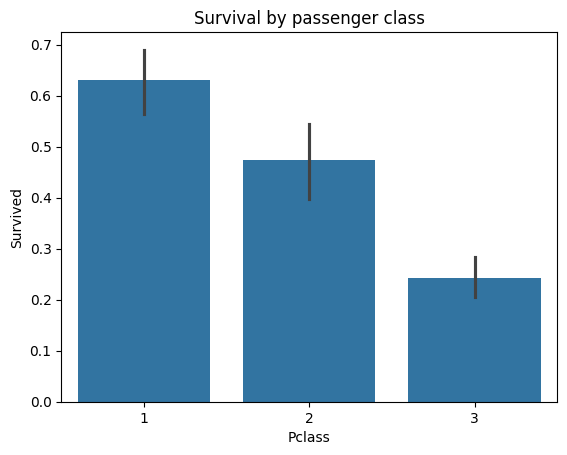

In [2]:
display(df.isna().sum().sort_values(ascending=False).head()); display(df.describe(include='all').T.head(15))
sns.barplot(data=df,x='Pclass',y='Survived'); plt.title('Survival by passenger class'); plt.show()

## Modify
Keep interpretable demographic and ticket variables, impute missing Age and Embarked values, standardize numeric fields, and one-hot encode categories.

In [3]:
features=['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']; X=df[features]; y=df['Survived']
num=['Pclass','Age','SibSp','Parch','Fare']; cat=['Sex','Embarked']
prep=ColumnTransformer([('num',Pipeline([('imp',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('imp',SimpleImputer(strategy='most_frequent')),('ohe',OneHotEncoder(handle_unknown='ignore'))]),cat)])
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=42,stratify=y)

## Model and Assess
Train an interpretable logistic-regression model and assess it on unseen data using accuracy, precision, recall, F1, and a confusion matrix.

Accuracy: 0.804
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



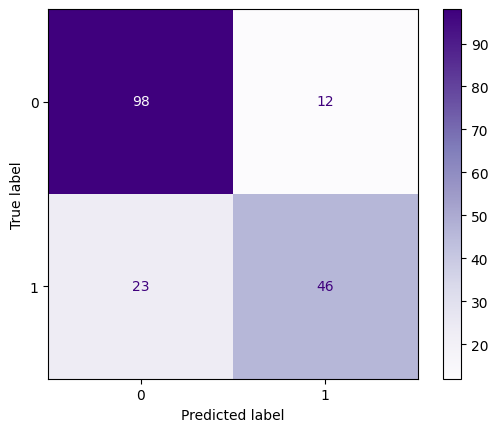

In [4]:
model=Pipeline([('prep',prep),('model',LogisticRegression(max_iter=1000))])
model.fit(Xtr,ytr); pred=model.predict(Xte)
print('Accuracy:',round(accuracy_score(yte,pred),3)); print(classification_report(yte,pred))
ConfusionMatrixDisplay.from_predictions(yte,pred,cmap='Purples'); plt.show()

## Assessment and Limitations
The test-set results indicate how well the selected features generalize to unseen passengers. Accuracy alone is insufficient when class errors have different consequences. This historical dataset is not a causal model of survival and should not be used for real-world individual decisions.

## Expanded Sample and Exploration

SEMMA begins with a purposeful sample and iterative exploration. We examine target balance, missingness, distributions, subgroup survival rates, and suspicious variables before modifying the data.

,dtype,missing,unique
Cabin,object,687,147
Age,float64,177,88
Embarked,object,2,3
PassengerId,int64,0,891
Name,object,0,891
Pclass,int64,0,3
Survived,int64,0,2
Sex,object,0,2
Parch,int64,0,7
SibSp,int64,0,7


Duplicate rows: 0


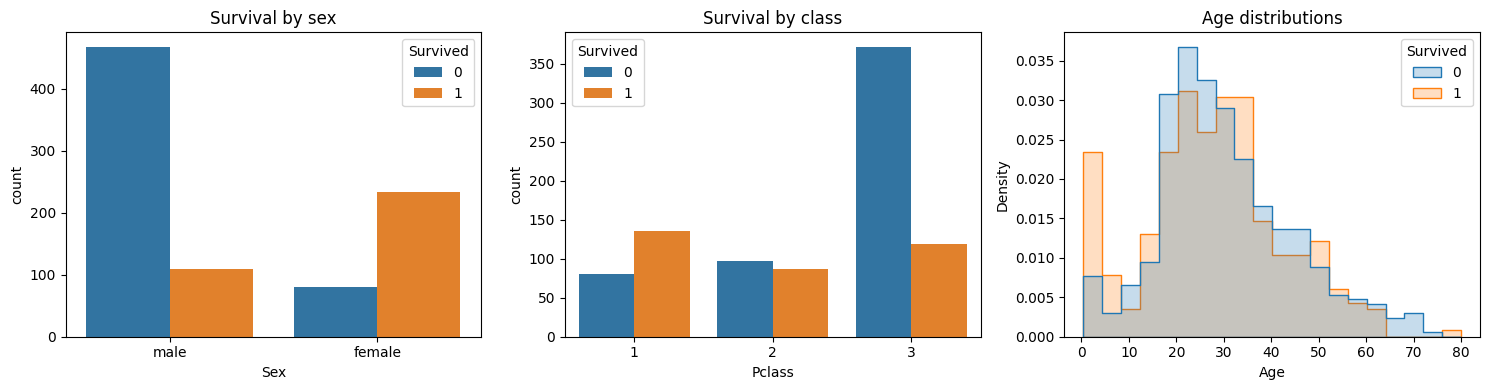

These patterns are descriptive and should not be interpreted as causal explanations.


In [5]:
audit = pd.DataFrame({"dtype":df.dtypes.astype(str),"missing":df.isna().sum(),"unique":df.nunique()}).sort_values("missing",ascending=False)
display(audit); print("Duplicate rows:", df.duplicated().sum())
fig, ax = plt.subplots(1,3,figsize=(15,4))
sns.countplot(data=df,x="Sex",hue="Survived",ax=ax[0]); ax[0].set_title("Survival by sex")
sns.countplot(data=df,x="Pclass",hue="Survived",ax=ax[1]); ax[1].set_title("Survival by class")
sns.histplot(data=df,x="Age",hue="Survived",bins=20,element="step",stat="density",common_norm=False,ax=ax[2]); ax[2].set_title("Age distributions")
plt.tight_layout(); plt.show()
print("These patterns are descriptive and should not be interpreted as causal explanations.")

## Modify: Feature Engineering and Leakage Control

The passenger name and ticket identifiers are excluded from the primary model because they can create high-cardinality patterns that are difficult to generalize. Family size and whether a passenger traveled alone provide interpretable derived features.

In [6]:
df2 = df.copy()
df2["FamilySize"] = df2["SibSp"] + df2["Parch"] + 1
df2["IsAlone"] = (df2["FamilySize"] == 1).astype(int)
features2 = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked","FamilySize","IsAlone"]
X2, y2 = df2[features2], df2["Survived"]
num2 = ["Pclass","Age","SibSp","Parch","Fare","FamilySize","IsAlone"]; cat2=["Sex","Embarked"]
prep2 = ColumnTransformer([("num",Pipeline([("imp",SimpleImputer(strategy="median")),("scale",StandardScaler())]),num2), ("cat",Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("ohe",OneHotEncoder(handle_unknown="ignore"))]),cat2)])
X2tr,X2te,y2tr,y2te=train_test_split(X2,y2,test_size=.2,random_state=42,stratify=y2)
print("Engineered features:", features2)

Engineered features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']


## Model Comparison and Validation

SEMMA requires assessment of the candidate model, not only a single score. We compare a linear model with a tree-based model and report repeated metrics on unseen data.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold
candidate_models = {
    "Logistic Regression": Pipeline([("prep",prep2),("model",LogisticRegression(max_iter=1000))]),
    "Decision Tree": Pipeline([("prep",prep2),("model",__import__("sklearn.tree",fromlist=["DecisionTreeClassifier"]).DecisionTreeClassifier(max_depth=5,random_state=42))]),
    "Random Forest": Pipeline([("prep",prep2),("model",RandomForestClassifier(n_estimators=200,max_depth=6,random_state=42))])
}
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
for name,candidate in candidate_models.items():
    s=cross_validate(candidate,X2,y2,cv=cv,scoring=["accuracy","precision","recall","f1"])
    print(name, {m:round(s["test_"+m].mean(),3) for m in ["accuracy","precision","recall","f1"]})

Logistic Regression {'accuracy': np.float64(0.801), 'precision': np.float64(0.759), 'recall': np.float64(0.71), 'f1': np.float64(0.733)}
Decision Tree {'accuracy': np.float64(0.81), 'precision': np.float64(0.819), 'recall': np.float64(0.652), 'f1': np.float64(0.724)}
Random Forest {'accuracy': np.float64(0.827), 'precision': np.float64(0.832), 'recall': np.float64(0.69), 'f1': np.float64(0.753)}


## SEMMA Assessment Narrative

The final choice should balance performance and interpretability. A model with slightly higher accuracy may be less useful if it has poor recall for survivors or fails on missing-age cases. The assessment therefore includes class-specific precision, recall, F1, confusion matrix, and cross-validation stability. The data are historical and the model is educational rather than a real decision system.

## Reproducibility and Deployment Considerations

For a reproducible scoring pipeline, save the preprocessing and model together, record the feature list and random seed, validate incoming columns, and monitor performance if labels become available. Any deployment would require privacy review and a clear statement that predictions should not be used to make decisions about real people.